# **5G deployment example on existing local infrastructure (2)**

### **Description**:
- #### Open5GS core with: AMF, AUSF, BSF, NSSF, NRF, PCF, SMF, UPF, UDM, UDR
- #### OCUDU gNB with USRP B210
- #### Quectel RM520N-GL (`qdon01`) as UE

## **0.**   Pre-requisites:

### Install `ifran`:

In [ ]:
! pip install ifran

Looking in indexes: https://pypi.org/simple, https://gitlab.inria.fr/api/v4/projects/70914/packages/pypi/simple
Processing /Users/zimabrou/Projects/5g_blueprint
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for orchestrator: filename=orchestrator-0.0.2-py3-none-any.whl size=805681 sha256=c592d71db6b9e9f7e4e8a7b9e17b2415619f04b28a0c66c2c1d8c857d2d9aca1
  Stored in directory: /private/var/folders/4j/8j63qg_x4y93h7cg9lzd1n90k524rf/T/pip-ephem-wheel-cache-vitcelo9/wheels/f0/64/b6/9ed48d267285130ce389b28fa77f5a9a081a8087d4487a8679
Successfully built orchestrator

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


Install the Ansible dependencies:

In [ ]:
! ansible-galaxy install -r ../../ansible/requirements.yaml

## Load input models:

- #### Meta Model:

In [ ]:
from ifran import MetaModel

metamodel = MetaModel.from_yaml(
"""
rus:
  b210:
    type: usrp
    model: b210
    txGainDB: 80
    rxGainDB: 40

ran:
  components:
    gnb:
      type: gnb
      config:
        radioConfiguration:
          nrBand: 78
          downlinkArfcn: 650000
          channelBandwidthMhz: 20
          prachConfigurationIndex: 1
          tddConfiguration:
            periodicityMilliseconds: 5
            nrofDownlinkSlots: 7
            nrofDownlinkSymbols: 6
            nrofUplinkSlots: 2
            nrofUplinkSymbols: 4
        ru: b210

ues:
  qdong01:
    type: cots
    config:
      supi: "001010000000017"
      authenticationData:
        k: "fec86ba6eb707ed08905757b1bb44b8f"
        opc: "C42449363BBAD02B66D16BC975D77CC1"
      subscriptions:
        - snssai: internet
          dnn: internet
      gnbs:
        - gnb
      nrBands:
        - 78
"""
)

- #### Deployment Model:

In [ ]:
from ifran import DeploymentModel

deployment_model = DeploymentModel.from_yaml(
"""
nodes:
  node1:
    is_provisioned: true
    provisioner: null
    ssh_info:
      hostname: ptb-04015558.inria.fr

  node2:
    is_provisioned: true
    provisioner: null
    ssh_info:
      hostname: pacify.inria.fr
      user: ubuntu
      sudo_password: ubuntu

rus:
  b210:
    is_provisioned: true
    provisioner: null

core:
  implementation: open5gs
  database_params:
    image:
      repository: "docker.io/mongo"
      image_tag: "7.0" # this is the mongodb version compatible with the machine's kernel version

ran:
  implementation: ocudu
  components:
    gnb:
      type: gnb
      advanced_config:
        srate: 23.04
"""
)

## **1.**   Kubernetes Deployement:

In [ ]:
from ifran import K8SManagement

k8s = K8SManagement(metamodel=metamodel, deployment_model=deployment_model)

#### Deploy Kubernetes only on `node1`:

In [ ]:
await k8s.deploy(nodes=["node1"])


PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [k8s/prepare : Set time zone to 'Europe/Paris' on 'ptb-04015558.inria.fr'] ***
[WARNING]: Host 'ptb-04015558.inria.fr' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
ok: [ptb-04015558.inria.fr]

TASK [k8s/prepare : Install base packages required for Kubernetes on 'ptb-04015558.inria.fr'] ***
changed: [ptb-04015558.inria.fr]

TASK [k8s/prepare : Ensure apt keyring directory exists on 'ptb-04015558.inria.fr'] ***
ok: [ptb-04015558.inria.fr]

TASK [k8s/prepare : Add Kubernetes apt signing key on 'ptb-04015558.inria.fr'] ***
changed: [ptb-04015558.inria.fr]

TASK [k8s/prepare : Convert Kubernetes apt key to keyring format on 'ptb-04015558.inria.fr'] ***
changed

## **2.**   5G Core Deployement:

In [ ]:
from ifran import CoreManagement

core = CoreManagement(k8s)

In [11]:
await core.deploy()


PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/prepare : Create Helm build directory for 'open5gs-database' chart] ***

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/prepare : Create Helm build directory for 'open5gs-ausf' chart] *****

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/prepare : Create Helm build directory for 'open5gs-amf' chart] ******

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/prepare : Create Helm build directory for 'open5gs-bsf' chart] ******

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/prepare : Create Helm build directory for 'open5gs-nssf' chart] *****

PLAY [ptb-04015558.inria.fr] ***************************************************

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/pr

### Check deployed pods with `kubectl`:

In [ ]:
from ifran import ProvisioningManagement

prov = ProvisioningManagement(core)

print(await prov.run_node_command(
    command=["kubectl", "get", "pods", "-n", "open5gs-core"],
    nodes=["node1"],
    become=True, quiet=True))

NAME                            READY   STATUS    RESTARTS   AGE
open5gs-amf-7b6dcfbfdf-szlzp    1/1     Running   0          2m8s
open5gs-ausf-5778d7548b-8whqj   1/1     Running   0          113s
open5gs-bsf-75cf9d7fb4-2lhv4    1/1     Running   0          18s
open5gs-database-0              1/1     Running   0          2m39s
open5gs-nrf-65d98494d7-mkbmv    1/1     Running   0          2m23s
open5gs-nssf-84cb8d64f7-tfpqd   1/1     Running   0          32s
open5gs-pcf-6f444b66c5-qtsf6    1/1     Running   0          79s
open5gs-smf-5c7c8d4c4c-8mfbs    1/1     Running   0          97s
open5gs-udm-886ffcdb8-rxktg     1/1     Running   0          62s
open5gs-udr-77bbf9559-x9cvg     1/1     Running   0          47s
open5gs-upf-fbcb65b44-b7pwj     1/1     Running   0          79s


## **3.**   RAN deployement:

### Check if USRP B210 is plugged in on `node1`:

In [ ]:
print(await prov.run_node_command(
    command=["lsusb"],
    nodes=["node1"],
    quiet=True))

Bus 001 Device 001: ID 1d6b:0002 Linux Foundation 2.0 root hub
Bus 001 Device 002: ID 0a5c:5832 Broadcom Corp. 5880
Bus 001 Device 003: ID 0c45:6717 Microdia Integrated_Webcam_HD
Bus 002 Device 001: ID 1d6b:0003 Linux Foundation 3.0 root hub
Bus 002 Device 002: ID 2500:0020 Ettus Research LLC USRP B210


#### Tune `node1` (reference: https://kb.ettus.com/USRP_Host_Performance_Tuning_Tips_and_Tricks):

In [ ]:
print(await prov.run_node_command(
    command=["apt", "install", "-y", "cpufrequtils"],
    nodes=["node1"],
    become=True, quiet=True))

Lecture des listes de paquets…
Construction de l'arbre des dépendances…
Lecture des informations d'état…
cpufrequtils est déjà la version la plus récente (008-2build2).
0 mis à jour, 0 nouvellement installés, 0 à enlever et 33 non mis à jour.


#### Set the CPU governor to performance for all cores:

In [ ]:
print(await prov.run_node_command(
    command=["bash", "-c", "for ((i=0;i<$(nproc --all);i++)); do cpufreq-set -c $i -r -g performance; done"],
    nodes=["node1"],
    become=True, quiet=True))

#### Verify that the CPU governor has been set:

In [ ]:
print(await prov.run_node_command(
    command=["cpufreq-info"],
    nodes=["node1"],
    become=True, quiet=True))

cpufrequtils 008: cpufreq-info (C) Dominik Brodowski 2004-2009
Veuillez rapportez les erreurs et les bogues à cpufreq@vger.kernel.org, s'il vous plait.
analyse du CPU 0 :
  pilote : intel_pstate
  CPUs which run at the same hardware frequency: 0
  CPUs which need to have their frequency coordinated by software: 0
  maximum transition latency: 4294.55 ms.
  limitation matérielle : 800 MHz - 4.30 GHz
  régulateurs disponibles : performance, powersave
  tactique actuelle : la fréquence doit être comprise entre 800 MHz et 4.30 GHz.
                  Le régulateur "performance" est libre de choisir la vitesse
                  dans cette plage de fréquences.
  la fréquence actuelle de ce CPU est 4.10 GHz.
analyse du CPU 1 :
  pilote : intel_pstate
  CPUs which run at the same hardware frequency: 1
  CPUs which need to have their frequency coordinated by software: 1
  maximum transition latency: 4294.55 ms.
  limitation matérielle : 800 MHz - 4.30 GHz
  régulateurs disponibles : performance,

#### Deploy OCUDU gNB:

In [ ]:
from ifran import RANManagement

ran = RANManagement(core)

In [15]:
await ran.deploy()


PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/prepare : Create Helm build directory for 'ocudu-gnb' chart] ********
[WARNING]: Host 'ptb-04015558.inria.fr' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
ok: [ptb-04015558.inria.fr]

TASK [helm/prepare : Copy local 'ocudu-gnb' Helm chart directory for 'ocudu-gnb'] ***
ok: [ptb-04015558.inria.fr]

TASK [helm/prepare : Render 'ocudu-gnb' Helm Chart.yaml file from Jinja template] ***
ok: [ptb-04015558.inria.fr]

TASK [helm/prepare : Render templated Helm files for 'ocudu-gnb'] **************
changed: [ptb-04015558.inria.fr] => (item=values.yaml)
changed: [ptb-04015558.inria.fr] => (item=config.yaml)

PLAY RECAP ****************************************

### Check gNB logs:

In [16]:
print(await ran.get_logs(components=["gnb"], quiet=True))

[INFO] [UHD] linux; GNU C++ version 13.3.0; Boost_108300; UHD_4.6.0.0-0-unknown
[INFO] [LOGGING] Fastpath logging disabled at runtime.
[DEBUG] [B200] the firmware image: /opt/uhd/4.6.0.0/share/uhd/images/usrp_b200_fw.hex
[INFO] [B200] Detected Device: B210
[INFO] [B200] Operating over USB 3.
[INFO] [B200] Initialize CODEC control...
[INFO] [B200] Initialize Radio control...
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband ban

## **3.**   Connect UE:

### Check if `qdong01` is plugged in on `node2`:

In [ ]:
print(await prov.run_node_command(
    command=["lsusb"],
    nodes=["node2"],
    quiet=True))

Bus 002 Device 002: ID 8087:8000 Intel Corp. Integrated Rate Matching Hub
Bus 002 Device 001: ID 1d6b:0002 Linux Foundation 2.0 root hub
Bus 001 Device 002: ID 8087:8008 Intel Corp. Integrated Rate Matching Hub
Bus 001 Device 001: ID 1d6b:0002 Linux Foundation 2.0 root hub
Bus 004 Device 001: ID 1d6b:0003 Linux Foundation 3.0 root hub
Bus 003 Device 017: ID 2c7c:0801 Quectel Wireless Solutions Co., Ltd. RM520N-GL
Bus 003 Device 003: ID 04ca:7034 Lite-On Technology Corp. HP HD Webcam
Bus 003 Device 002: ID 138a:003f Validity Sensors, Inc. VFS495 Fingerprint Reader
Bus 003 Device 005: ID 8087:07da Intel Corp. Centrino Bluetooth Wireless Transceiver
Bus 003 Device 004: ID 03f0:0024 HP, Inc KU-0316 Keyboard
Bus 003 Device 001: ID 1d6b:0002 Linux Foundation 2.0 root hub


### Initialize UE:

In [ ]:
print(await prov.run_node_command(
    command=["qhat-init", "--dnn", "internet"],
    nodes=["node2"],
    become=True, quiet=True))

[2026-10-05 04:21:40] 🔧 qhat-init — multi-modem init
[2026-10-05 04:21:42] ❌ No modem AT port found.


> *Note*: If the command above fails with an error like this:
> ```bash
> [2026-10-05 04:21:40] 🔧 qhat-init — multi-modem init
> [2026-10-05 04:21:42] ❌ No modem AT port found.
> ```
> Then uncomment and run the `stop.sh` command and the `qhat-init` command again::

In [ ]:
# print(await prov.run_node_command(
#     command=["stop.sh"],
#     nodes=["node2"],
#     become=True, quiet=True))

---- mbimcli -d /dev/cdc-wdm0 -p --disconnect=0
---- mbimcli -p -d /dev/cdc-wdm0 --set-radio-state=off
[/dev/cdc-wdm0] Radio state retrieved:
	     Hardware radio state: 'on'
	     Software radio state: 'off'
-------Removing the wwan0 -------


In [ ]:
# print(await prov.run_node_command(
#     command=["qhat-init", "--dnn", "internet"],
#     nodes=["node2"],
#     become=True, quiet=True))

[/dev/cdc-wdm0] Radio state retrieved:
	     Hardware radio state: 'on'
	     Software radio state: 'off'
waiting for command AT+CFUN=0
AT+CFUN=0
waiting for command AT+CFUN=0
OK
['AT+CFUN=0', 'OK']
[/dev/cdc-wdm0] Radio state retrieved:
	     Hardware radio state: 'on'
	     Software radio state: 'on'
[/dev/cdc-wdm0] Radio state retrieved:
	     Hardware radio state: 'on'
	     Software radio state: 'off'
[2026-10-05 04:25:33] 🔧 qhat-init — multi-modem init
[2026-10-05 04:25:35] ✅ Using modem AT port: /dev/ttyUSB3
[2026-10-05 04:25:37] Detected modem model: RM520N
[2026-10-05 04:25:37] Selected mode: MBIM
[2026-10-05 04:25:37] ✅ Keeping MBIM mode.
[2026-10-05 04:25:37] 🧹 Clearing existing APN profiles...
[2026-10-05 04:25:44] ✅ All APN profiles cleared.
[2026-10-05 04:25:44] ⚙️ Configuring DNN / NSSAI
[2026-10-05 04:25:44] Set a single APN with DNN internet
[2026-10-05 04:25:46] No specific NSSAI set
[2026-10-05 04:25:48] ⚙️ Enabling NR5G mode only...
[2026-10-05 04:25:50] ⚙️ Setting 

### Connect UE:

In [ ]:
print(await prov.run_node_command(
    command=["start.sh", "-F", "internet"],
    nodes=["node2"],
    become=True, quiet=True))

running /usr/local/bin/start.sh with parameters: DNN0=internet, no DNN1, quiet false
-------Setting up wwan0 for testing-------
---- mbimcli -p -d /dev/cdc-wdm0 --set-radio-state=on
[/dev/cdc-wdm0] Radio state retrieved:
	     Hardware radio state: 'on'
	     Software radio state: 'on'
---- mbimcli -p -d /dev/cdc-wdm0 --attach-packet-service
[/dev/cdc-wdm0] Successfully attached to packet service

[/dev/cdc-wdm0] Packet service status:
	         Network error: 'none'
	  Packet service state: 'attached'
	Available data classes: 'custom'
	          Uplink speed: '1497000000 bps'
	        Downlink speed: '3951000000 bps'
---- mbimcli -p -d /dev/cdc-wdm0 --connect=session-id=0,access-string=internet,ip-type=ipv4
[/dev/cdc-wdm0] Successfully connected

[/dev/cdc-wdm0] Connection status:
	      Session ID: '0'
	Activation state: 'activated'
	Voice call state: 'none'
	         IP type: 'ipv4'
	    Context type: 'internet'
	   Network error: 'none'

[/dev/cdc-wdm0] IPv4 configuration available

### Check if UE got a PDU session:

In [ ]:
output = (await prov.run_node_command(
    command=["ip", "-4", "-o", "addr", "show", "wwan0"],
    nodes=["node2"],
    quiet=True))

output

'19: wwan0    inet 11.1.1.2/30 brd 11.1.1.3 scope global noprefixroute wwan0\\       valid_lft forever preferred_lft forever'

#### Get UE IP:

In [22]:
ip = output.split()[3].split("/")[0]
ip

'11.1.1.2'

#### Check gNB logs:

In [23]:
print(await ran.get_logs(components=["gnb"], quiet=True))

[INFO] [UHD] linux; GNU C++ version 13.3.0; Boost_108300; UHD_4.6.0.0-0-unknown
[INFO] [LOGGING] Fastpath logging disabled at runtime.
[DEBUG] [B200] the firmware image: /opt/uhd/4.6.0.0/share/uhd/images/usrp_b200_fw.hex
[INFO] [B200] Detected Device: B210
[INFO] [B200] Operating over USB 3.
[INFO] [B200] Initialize CODEC control...
[INFO] [B200] Initialize Radio control...
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband bandwidth too large for current sample rate. Setting bandwidth to: 5e+07
[DEBUG] [AD936X] baseband ban

### Test connectivity:

In [ ]:
print(await prov.run_node_command(
    command=["ping", "-c", "6", "11.1.1.1", "-I", "wwan0"],
    nodes=["node2"],
    quiet=True))

PING 11.1.1.1 (11.1.1.1) from 11.1.1.2 wwan0: 56(84) bytes of data.
64 bytes from 11.1.1.1: icmp_seq=1 ttl=64 time=27.1 ms
64 bytes from 11.1.1.1: icmp_seq=2 ttl=64 time=25.8 ms
64 bytes from 11.1.1.1: icmp_seq=3 ttl=64 time=23.7 ms
64 bytes from 11.1.1.1: icmp_seq=4 ttl=64 time=21.7 ms
64 bytes from 11.1.1.1: icmp_seq=5 ttl=64 time=19.7 ms
64 bytes from 11.1.1.1: icmp_seq=6 ttl=64 time=37.7 ms

--- 11.1.1.1 ping statistics ---
6 packets transmitted, 6 received, 0% packet loss, time 5009ms
rtt min/avg/max/mdev = 19.667/25.940/37.686/5.794 ms


In [ ]:
print(await prov.run_node_command(
    command=["ping", "-c", "6", "8.8.8.8", "-I", "wwan0"],
    nodes=["node2"],
    quiet=True))

PING 8.8.8.8 (8.8.8.8) from 11.1.1.2 wwan0: 56(84) bytes of data.
64 bytes from 8.8.8.8: icmp_seq=1 ttl=114 time=34.4 ms
64 bytes from 8.8.8.8: icmp_seq=2 ttl=114 time=32.8 ms
64 bytes from 8.8.8.8: icmp_seq=3 ttl=114 time=30.7 ms
64 bytes from 8.8.8.8: icmp_seq=4 ttl=114 time=28.7 ms
64 bytes from 8.8.8.8: icmp_seq=5 ttl=114 time=26.7 ms
64 bytes from 8.8.8.8: icmp_seq=6 ttl=114 time=24.7 ms

--- 8.8.8.8 ping statistics ---
6 packets transmitted, 6 received, 0% packet loss, time 5010ms
rtt min/avg/max/mdev = 24.690/29.663/34.384/3.357 ms


## **4.**   Test Scenario: Iperf

#### Install `iperf3` on both machines:

In [78]:
await prov.run_node_command(command=["sh", "-c", "DEBIAN_FRONTEND=noninteractive apt install -y iperf3"], become=True, quiet=True)

{'ptb-04015558.inria.fr': "Lecture des listes de paquets…\nConstruction de l'arbre des dépendances…\nLecture des informations d'état…\nLes NOUVEAUX paquets suivants seront installés\xa0:\n  iperf3\n0 mis à jour, 1 nouvellement installés, 0 à enlever et 33 non mis à jour.\nIl est nécessaire de prendre 19,0 ko dans les archives.\nAprès cette opération, 89,1 ko d'espace disque supplémentaires seront utilisés.\nRéception de\xa0:1 http://si-repository.inria.fr/mirrors/ubuntu noble/universe amd64 iperf3 amd64 3.16-1build2 [19,0 kB]\nPréconfiguration des paquets...\n19,0 ko réceptionnés en 0s (351 ko/s)\nSélection du paquet iperf3 précédemment désélectionné.\r\n(Lecture de la base de données... \r(Lecture de la base de données... 5%\r(Lecture de la base de données... 10%\r(Lecture de la base de données... 15%\r(Lecture de la base de données... 20%\r(Lecture de la base de données... 25%\r(Lecture de la base de données... 30%\r(Lecture de la base de données... 35%\r(Lecture de la base de donnée

#### Add necessary routing rules for the UE on `pacify.inria.fr` machine:

In [26]:
await prov.run_node_command(
    command=["ip", "route", "add", "11.1.1.0/29", "dev", "wwan0", "src", ip, "table", "100"],
    nodes=["pacify.inria.fr"],
    become=True, quiet=True,
)

{'pacify.inria.fr': ''}

In [27]:
await prov.run_node_command(
    command=["ip", "route", "add", "default", "via", "11.1.1.1", "dev", "wwan0", "src", ip, "table", "100"],
    nodes=["pacify.inria.fr"],
    become=True, quiet=True,
)

{'pacify.inria.fr': ''}

In [28]:
await prov.run_node_command(
    command=["ip", "rule", "add", "from", f"{ip}/32", "table", "100"],
    nodes=["pacify.inria.fr"],
    become=True, quiet=True,
)

{'pacify.inria.fr': ''}

#### Start `iperf3` server on `node1` in the background for one test:

In [ ]:
await prov.run_node_command(command=["iperf3", "-s", "-1", "-D"], nodes=["node1"], quiet=True)

{'ptb-04015558.inria.fr': ''}

#### Start `iperf3` client on `node2` for 1 minute in downlink path with TCP:

In [ ]:
downlink = (await prov.run_node_command(
    command=["iperf3", "-c", "ptb-04015558.inria.fr", "-B", ip, "-t", "60", "-R", "-J"],
    nodes=["node2"],
    quiet=True))

### Then in the uplink:

In [ ]:
await prov.run_node_command(command=["iperf3", "-s", "-1", "-D"], nodes=["node1"], quiet=True)

{'ptb-04015558.inria.fr': ''}

In [ ]:
uplink = (await prov.run_node_command(
    command=["iperf3", "-c", "ptb-04015558.inria.fr", "-B", ip, "-t", "60", "-J"],
    nodes=["node2"],
    quiet=True))

#### Plot `iperf3` bitrate:

In [87]:
! pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [88]:
! pip install pandas

  Using cached pandas-3.0.6-cp314-cp314-macosx_11_0_arm64.whl.metadata (79 kB)
Using cached pandas-3.0.6-cp314-cp314-macosx_11_0_arm64.whl (10.2 MB)

[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


In [33]:
import json
import matplotlib.pyplot as plt
import pandas as pd

def plot_throughput(iperf_json: str, title: str):
    # load the iperf3 JSON
    data = json.loads(iperf_json)

    # extract interval timestamps and speeds
    time_points = []
    bandwidth_mbps = []

    for interval in data["intervals"]:
        # the 'sum' object aggregates all parallel streams if you used the -P flag
        sum_data = interval["sum"]
        
        # iperf3 tracks time from the start of the test (e.g., end of second 1, second 2)
        time_points.append(sum_data["end"])
        
        # convert bits per second to Mbps
        mbps = sum_data["bits_per_second"] / 1_000_000
        bandwidth_mbps.append(mbps)

    # create a DataFrame for easy manipulation
    df = pd.DataFrame({"Time (s)": time_points, "Bitrate (Mbps)": bandwidth_mbps})

    # generate the plot
    plt.figure(figsize=(10, 5))
    plt.plot(df["Time (s)"], df["Bitrate (Mbps)"], marker='o', color='b', linestyle='-', linewidth=2)

    plt.title(title)
    plt.xlabel("Time (s)")
    plt.ylabel("Bitrate (Mbps)")
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.ylim(bottom=0)  # force Y-axis to start at 0

    # display the graph
    plt.show()


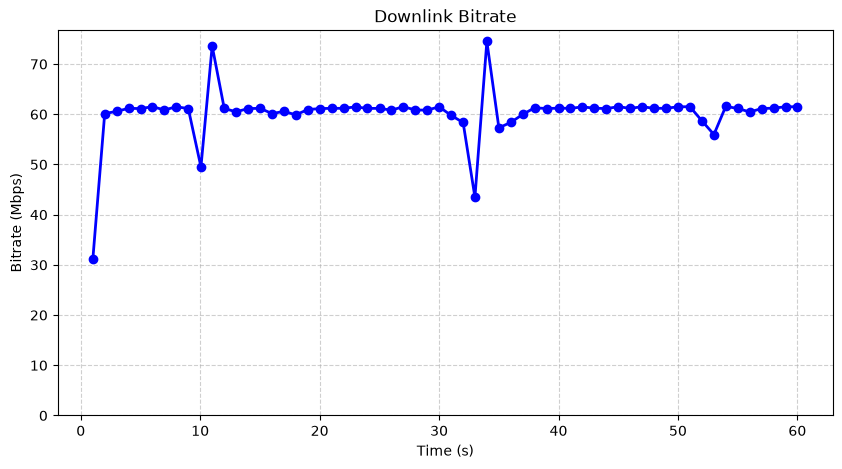

In [34]:
plot_throughput(downlink, "Downlink Bitrate")

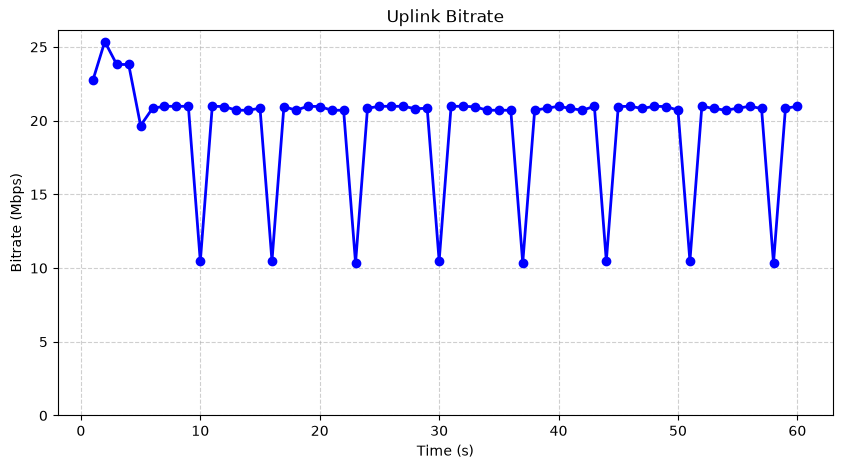

In [35]:
plot_throughput(uplink, "Uplink Bitrate")

### Save meta model and deployment model:

In [36]:
ran.output(metamodel_file="output_metamodel.yaml", deployment_model_file="output_deployment_model.yaml")

(MetaModel(core=Core(components={'amf': AMFComponent(category=<Category5G.CORE: 'core'>, type=<CoreComponentType.AMF: 'amf'>, config=AMFConfig(sbi=SBI(interfaceName='eth0', ipv4EndPointAddress=IPv4Address('0.0.0.0'), ipv6EndPointAddress=None, port=80, protocol='TCP', scheme='http', apiVersion='v1', tls=TLS(enabled=False, certificate=None, privateKey=None)), nrfUri=None, n2=NGAP(interfaceName='eth0', ipv4EndPointAddress=IPv4Address('0.0.0.0'), ipv6EndPointAddress=None, port=38412, protocol='SCTP'), guamiList=[GUAMI(plmnId=PLMN(mcc=1, mnc=1, mncLength=2, plmnId='00101'), amfRegionId=2, amfSetId=1, amfPointer=0, amfId=131136)], taiList=[TAI(plmnId=PLMN(mcc=1, mnc=1, mncLength=2, plmnId='00101'), tac=1)], plmnList=[PLMNSupportItem(plmnId=PLMN(mcc=1, mnc=1, mncLength=2, plmnId='00101'), snssaiList=['internet'])], securityAlgorithmConfiguration=SecurityAlgorithmConfiguration(integrityOrder=[<IntegrityAlgorithm.NIA2: 'nia2'>, <IntegrityAlgorithm.NIA1: 'nia1'>, <IntegrityAlgorithm.NIA0: 'nia0'

## Cleanup:

- #### Disconnect UE:

In [ ]:
# from ifran import ProvisioningManagement

# prov = ProvisioningManagement(metamodel_file="output_metamodel.yaml", deployment_model_file="output_deployment_model.yaml")

# print(await prov.run_node_command(
#     command=["stop.sh"],
#     nodes=["node2"],
#     become=True, quiet=True))

---- mbimcli -d /dev/cdc-wdm0 -p --disconnect=0
---- mbimcli -p -d /dev/cdc-wdm0 --set-radio-state=off
[/dev/cdc-wdm0] Radio state retrieved:
	     Hardware radio state: 'on'
	     Software radio state: 'off'
-------Removing the wwan0 -------


- #### Remove RAN:

In [ ]:
# from ifran import RANManagement

# ran = RANManagement(metamodel_file="output_metamodel.yaml", deployment_model_file="output_deployment_model.yaml")

# await ran.remove()


PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/uninstall : Uninstall 'ocudu-gnb' Helm chart] ***********************
[WARNING]: Host 'ptb-04015558.inria.fr' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
[WARNING]: Deprecation warnings can be disabled by setting `deprecation_warnings=False` in ansible.cfg.
[DEPRECATION WARNING]: The 'status.values' return value is deprecated and will be removed in version 8.0.0. Use 'status.release_values' instead. This feature will be removed from collection 'kubernetes.core' version 8.0.0.
changed: [ptb-04015558.inria.fr]

TASK [helm/uninstall : Wait for 'ocudu-gnb' pod to be deleted] *****************
ok: [ptb-04015558.inria.fr]

TASK [helm/uninstall : Clean up

- #### Remove 5G core:

In [ ]:
# from ifran import CoreManagement

# core = CoreManagement(metamodel_file="output_metamodel.yaml", deployment_model_file="output_deployment_model.yaml")

# await core.remove()


PLAY [ptb-04015558.inria.fr] ***************************************************

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/uninstall : Uninstall 'open5gs-amf' Helm chart] *********************

TASK [helm/uninstall : Uninstall 'open5gs-database' Helm chart] ****************

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/uninstall : Uninstall 'open5gs-pcf' Helm chart] *********************

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/uninstall : Uninstall 'open5gs-nrf' Helm chart] *********************

PLAY [ptb-04015558.inria.fr] ***************************************************

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/uninstall : Uninstall 'open5gs-bsf' Helm chart] *********************

PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [helm/unin

- #### Remove Kubernetes:

In [ ]:
# from ifran import K8SManagement

# k8s = K8SManagement(metamodel_file="output_metamodel.yaml", deployment_model_file="output_deployment_model.yaml")

# await k8s.remove()


PLAY [ptb-04015558.inria.fr] ***************************************************

TASK [k8s/remove : Check if kubeadm exists  on 'ptb-04015558.inria.fr'] ********
[WARNING]: Host 'ptb-04015558.inria.fr' is using the discovered Python interpreter at '/usr/bin/python3.12', but future installation of another Python interpreter could cause a different interpreter to be discovered. See https://docs.ansible.com/ansible-core/2.21/reference_appendices/interpreter_discovery.html for more information.
ok: [ptb-04015558.inria.fr]

TASK [k8s/remove : Reset Kubernetes node state  on 'ptb-04015558.inria.fr'] ****
ok: [ptb-04015558.inria.fr]

TASK [k8s/remove : Remove Kubernetes manifests  on 'ptb-04015558.inria.fr'] ****
changed: [ptb-04015558.inria.fr] => (item=/etc/kubernetes/manifests)

TASK [k8s/remove : Stop kubelet, containerd systemd services  on 'ptb-04015558.inria.fr'] ***
changed: [ptb-04015558.inria.fr] => (item=kubelet)
changed: [ptb-04015558.inria.fr] => (item=containerd)

TASK [k8s/re